# CNN với Fashion-MNIST

## 1. Load và xem dữ liệu
Fashion-MNIST gồm ảnh xám 28×28, 10 lớp quần áo.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import fashion_mnist
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()
class_names = ["T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"]
print(x_train.shape, x_test.shape)

(60000, 28, 28) (10000, 28, 28)


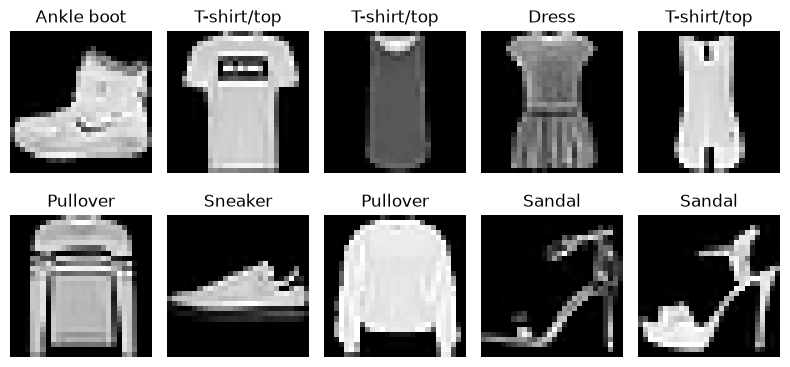

In [2]:
plt.figure(figsize=(8,4))
for i in range(10):
    plt.subplot(2,5,i+1); plt.imshow(x_train[i], cmap='gray'); plt.title(class_names[y_train[i]]); plt.axis('off')
plt.tight_layout(); plt.show()

**Giải thích:** mỗi ảnh biểu diễn một sản phẩm thời trang; một số lớp có hình dạng gần giống nhau nên bài toán khó hơn MNIST chữ số.

## 2. CNN from scratch bằng NumPy
Tự viết các phép toán cơ bản để thấy luồng **Convolution → ReLU → Max Pooling**.

In [3]:
def conv2d(image, kernel):
    h,w=image.shape; kh,kw=kernel.shape
    out=np.zeros((h-kh+1,w-kw+1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            out[i,j]=np.sum(image[i:i+kh,j:j+kw]*kernel)
    return out

def relu(x): return np.maximum(0,x)

def max_pool(x,size=2):
    h,w=x.shape; out=np.zeros((h//size,w//size))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            out[i,j]=np.max(x[i*size:(i+1)*size,j*size:(j+1)*size])
    return out

kernel=np.array([[1,0,-1],[1,0,-1],[1,0,-1]])
img=x_train[0].astype(float)/255
conv=relu(conv2d(img,kernel)); pool=max_pool(conv)
print(img.shape, conv.shape, pool.shape)

(28, 28) (26, 26) (13, 13)


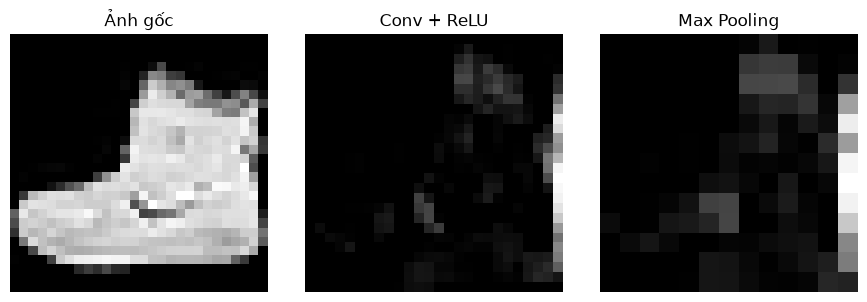

In [4]:
plt.figure(figsize=(9,3))
for k,(im,t) in enumerate([(img,'Ảnh gốc'),(conv,'Conv + ReLU'),(pool,'Max Pooling')]):
    plt.subplot(1,3,k+1); plt.imshow(im,cmap='gray'); plt.title(t); plt.axis('off')
plt.tight_layout(); plt.show()

**Giải thích:** convolution làm nổi bật cạnh/đặc trưng, ReLU bỏ giá trị âm, pooling giảm kích thước nhưng giữ đặc trưng mạnh.

## 3. CNN bằng TensorFlow/Keras

In [5]:
import tensorflow as tf
from tensorflow.keras import layers, models

Xtr=(x_train/255.0).astype('float32')[...,None]
Xte=(x_test/255.0).astype('float32')[...,None]

model=models.Sequential([
    layers.Conv2D(32,3,activation='relu',input_shape=(28,28,1)),
    layers.MaxPooling2D(2),
    layers.Conv2D(64,3,activation='relu'),
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dense(64,activation='relu'),
    layers.Dense(10,activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history=model.fit(Xtr,y_train,epochs=5,batch_size=128,validation_split=0.1,verbose=1)

C:\Users\Dat\anaconda3\envs\cnn_env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 28s 61ms/step - accuracy: 0.7875 - loss: 0.5972 - val_accuracy: 0.8423 - val_loss: 0.4321
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 26s 61ms/step - accuracy: 0.8649 - loss: 0.3778 - val_accuracy: 0.8725 - val_loss: 0.3504
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 24s 56ms/step - accuracy: 0.8826 - loss: 0.3282 - val_accuracy: 0.8830 - val_loss: 0.3160
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 22s 52ms/step - accuracy: 0.8933 - loss: 0.2977 - val_accuracy: 0.8915 - val_loss: 0.2970
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 26s 60ms/step - accuracy: 0.9008 - loss: 0.2744 - val_accuracy: 0.8945 - val_loss: 0.2946


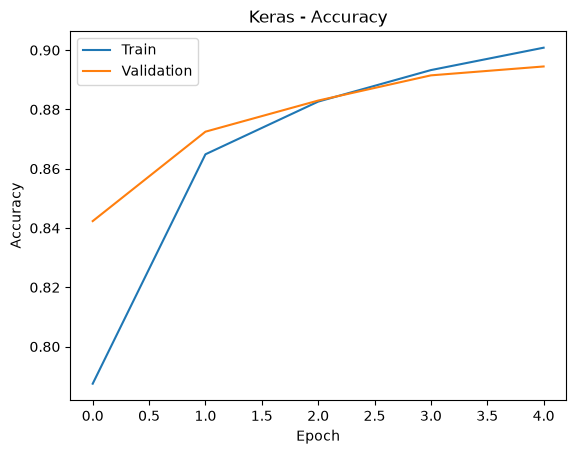

In [6]:
plt.plot(history.history['accuracy'],label='Train')
plt.plot(history.history['val_accuracy'],label='Validation')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.title('Keras - Accuracy'); plt.legend(); plt.show()

**Giải thích:** hai đường cùng tăng và gần nhau cho thấy mô hình học tốt; nếu train tăng nhưng validation giảm thì có thể overfitting.

Test accuracy: 0.8863000273704529


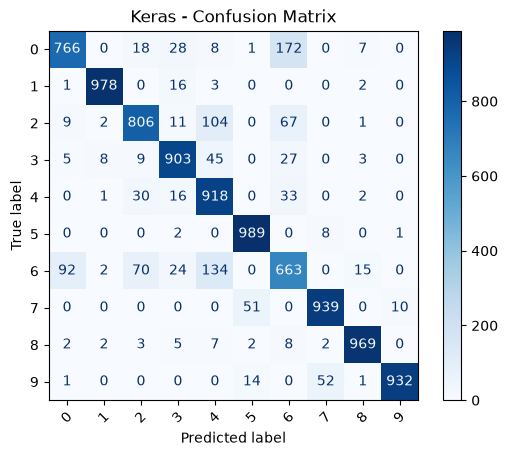

In [7]:
test_loss,test_acc=model.evaluate(Xte,y_test,verbose=0)
print('Test accuracy:',test_acc)
y_pred=np.argmax(model.predict(Xte,verbose=0),axis=1)
ConfusionMatrixDisplay(confusion_matrix(y_test,y_pred)).plot(cmap='Blues',xticks_rotation=45)
plt.title('Keras - Confusion Matrix'); plt.show()

**Giải thích:** các giá trị lớn trên đường chéo chính là dự đoán đúng; ô ngoài đường chéo là các lớp bị nhầm.

## 4. CNN bằng PyTorch

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
Xtr_t=torch.tensor(Xtr.transpose(0,3,1,2),dtype=torch.float32)
ytr_t=torch.tensor(y_train,dtype=torch.long)
loader=DataLoader(TensorDataset(Xtr_t,ytr_t),batch_size=128,shuffle=True)

class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(
            nn.Conv2d(1,32,3),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(32,64,3),nn.ReLU(),nn.MaxPool2d(2),
            nn.Flatten(),nn.Linear(64*5*5,64),nn.ReLU(),nn.Linear(64,10))
    def forward(self,x): return self.net(x)

torch_model=FashionCNN().to(device)
criterion=nn.CrossEntropyLoss(); optimizer=optim.Adam(torch_model.parameters(),lr=0.001)

In [9]:
accs=[]
for epoch in range(5):
    torch_model.train(); correct=total=0
    for xb,yb in loader:
        xb,yb=xb.to(device),yb.to(device)
        optimizer.zero_grad(); out=torch_model(xb); loss=criterion(out,yb)
        loss.backward(); optimizer.step()
        pred=out.argmax(1); correct+=(pred==yb).sum().item(); total+=yb.size(0)
    acc=correct/total; accs.append(acc); print(f'Epoch {epoch+1}: {acc:.4f}')

Epoch 1: 0.7823
Epoch 2: 0.8638
Epoch 3: 0.8787
Epoch 4: 0.8914
Epoch 5: 0.8968


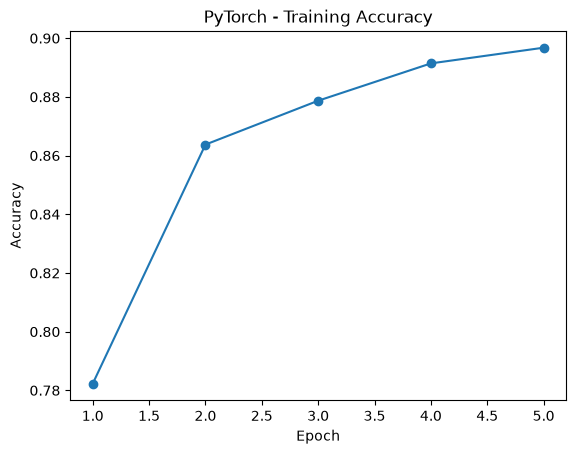

In [10]:
plt.plot(range(1,6),accs,marker='o'); plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.title('PyTorch - Training Accuracy'); plt.show()

**Giải thích:** accuracy tăng qua các epoch cho thấy mô hình đang học tốt hơn từ dữ liệu.

TensorFlow/Keras: 0.8863
PyTorch         : 0.8863


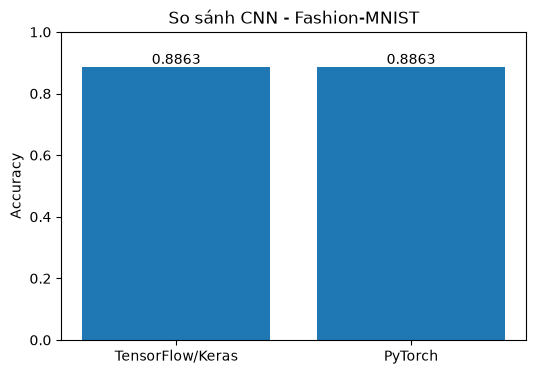

In [13]:
# SO SÁNH TENSORFLOW/KERAS VÀ PYTORCH

# 1. Accuracy của TensorFlow/Keras
_, keras_acc = model.evaluate(Xte, y_test, verbose=0)

# 2. Tạo tập test cho PyTorch
Xte_t = torch.tensor(
    Xte.transpose(0, 3, 1, 2),
    dtype=torch.float32
)

yte_t = torch.tensor(
    y_test,
    dtype=torch.long
)

test_loader = DataLoader(
    TensorDataset(Xte_t, yte_t),
    batch_size=256,
    shuffle=False
)

# 3. Accuracy của PyTorch
torch_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        output = torch_model(xb)
        pred = output.argmax(1)

        correct += (pred == yb).sum().item()
        total += yb.size(0)

pytorch_acc = correct / total

# 4. In kết quả
print(f"TensorFlow/Keras: {keras_acc:.4f}")
print(f"PyTorch         : {pytorch_acc:.4f}")

# 5. Vẽ biểu đồ
methods = ["TensorFlow/Keras", "PyTorch"]
accuracy = [keras_acc, pytorch_acc]

plt.figure(figsize=(6, 4))
bars = plt.bar(methods, accuracy)

plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("So sánh CNN - Fashion-MNIST")

for bar, value in zip(bars, accuracy):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.01,
        f"{value:.4f}",
        ha="center"
    )

plt.show()

Biểu đồ so sánh Accuracy trên tập test của hai cách cài đặt CNN:

- **TensorFlow/Keras** có cú pháp ngắn gọn, dễ xây dựng và huấn luyện mô hình.
- **PyTorch** cần viết quá trình huấn luyện chi tiết hơn nhưng linh hoạt và dễ kiểm soát.
- Hai mô hình có kiến trúc tương đối giống nhau nên Accuracy thường không chênh lệch quá lớn.
- CNN from scratch ở phần trên chỉ minh họa Convolution, ReLU và Max Pooling nên chưa có Accuracy để so sánh.

## 5. Giải thích các hàm chính
- `Conv2D/Conv2d`: trích xuất đặc trưng ảnh.
- `ReLU`: thay giá trị âm bằng 0.
- `MaxPooling`: giảm kích thước feature map.
- `Flatten`: chuyển feature map thành vector.
- `Dense/Linear`: lớp fully connected để phân loại.
- `softmax`: chuyển đầu ra thành xác suất lớp.
- `Adam`: tối ưu trọng số.
- `CrossEntropyLoss`: đo sai số phân loại.
- `backward()`: tính gradient.
- `optimizer.step()`: cập nhật trọng số.